**Objetivo:** Treinar e avaliar os baselines (SVM, Random Forest, XGBoost) com `GridSearchCV` nos 5 folds por site.

**Entradas:** `Data/processed/dataset_abide_processado.pkl` (notebook 07).

**Processamento:** `StandardScaler` ajustado só no treino de cada fold; métricas Accuracy, F1 e AUC-ROC; matrizes de confusão.

**Saídas:** `Results/08_resultados_baselines.csv`, `Models/08_modelos_baselines.joblib`, `Figures/08_*.png`.

In [ ]:
# ------------------------------------------------------------
# Configuração do projeto (execução local — VS Code)
# Garante que a raiz do projeto esteja no sys.path, funcionando tanto se o
# diretório de trabalho do kernel for notebooks/ quanto a raiz do projeto.
# ------------------------------------------------------------
import sys
from pathlib import Path

_raiz = Path.cwd().resolve()
for _cand in (_raiz, *_raiz.parents):
    if (_cand / 'src' / 'config.py').exists():
        _raiz = _cand
        break
else:
    raise RuntimeError(
        'Não foi possível localizar a pasta src/config.py a partir de '
        f'{Path.cwd()}. Abra a pasta TCC_TEA_TDAH/ no VS Code.'
    )
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))

import os
import random
import numpy as np

from src.config import BASE_DIR, PATHS, SEED, criar_pastas
from src.utils import exigir_arquivo

criar_pastas()

random.seed(SEED)
np.random.seed(SEED)

print('Projeto (BASE_DIR) =', BASE_DIR)

In [2]:
from nilearn.connectome import sym_matrix_to_vec

from sklearn.model_selection import (
    StratifiedGroupKFold,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

from xgboost import XGBClassifier

print('Bibliotecas carregadas com sucesso.')

Bibliotecas carregadas com sucesso.


In [3]:
exigir_arquivo(PATHS['processed'] / 'dataset_abide_processado.pkl', '07_Preparacao_Dados_ABIDE.ipynb')

import os
import pickle
import pandas as pd
import numpy as np
from nilearn.connectome import sym_matrix_to_vec
from sklearn.model_selection import StratifiedGroupKFold

processed_path = os.path.join(
    PATHS['processed'],
    'dataset_abide_processado.pkl'
)

try:

    print('Tentando carregar:')
    print(processed_path)
    print()

    with open(processed_path, 'rb') as f:
        dataset = pickle.load(f)

    X = dataset['X']
    y = dataset['y']
    groups = dataset['groups']
    folds = dataset['folds']

    print('==========================================')
    print('Dataset carregado diretamente do PKL')
    print('==========================================')

except TypeError as e:

    if 'StringDtype' not in str(e):

        raise

    print('==========================================')
    print('INCOMPATIBILIDADE DETECTADA NO PKL')
    print('==========================================')
    print()
    print('O arquivo foi salvo com uma versão diferente')
    print('do pandas.')
    print()
    print('Mensagem original:')
    print(e)
    print()
    print('Reconstruindo o dataset a partir das')
    print('matrizes de conectividade já processadas...')
    print()

    # --------------------------------------------------------
    # Arquivo original das matrizes de conectividade
    # --------------------------------------------------------

    connectivity_path = os.path.join(
        PATHS['conectivity'],
        'connectivity_matrices_abide_validado.pkl'
    )

    phenotypic_path = os.path.join(
        PATHS['raw'],
        'phenotypic_abide.csv'
    )

    print('Carregando matrizes:')
    print(connectivity_path)

    with open(connectivity_path, 'rb') as f:
        conn_dict = pickle.load(f)

    print('Matrizes carregadas.')

    # --------------------------------------------------------
    # Carregar fenotípico
    # --------------------------------------------------------

    phenotypic = pd.read_csv(
        phenotypic_path,
        index_col=0
    )

    print('Fenotípico carregado.')

    # --------------------------------------------------------
    # IDs dos participantes
    # --------------------------------------------------------

    sub_ids = np.array(
        list(conn_dict.keys()),
        dtype=str
    )

    # --------------------------------------------------------
    # Matrizes de conectividade
    # --------------------------------------------------------

    matrices = np.array(
        [conn_dict[s] for s in sub_ids]
    )

    print('Matrizes:', matrices.shape)

    # --------------------------------------------------------
    # Vetorização da matriz de conectividade
    #
    # Matriz simétrica:
    #
    # 200 x 200
    #
    # Número de conexões únicas:
    #
    # 200 * 199 / 2 = 19.900
    # --------------------------------------------------------

    X = sym_matrix_to_vec(
        matrices,
        discard_diagonal=True
    )

    # --------------------------------------------------------
    # Rótulos
    #
    # DX_GROUP:
    # 1 = TEA
    # 2 = Controle
    # --------------------------------------------------------

    y_original = phenotypic.loc[
        sub_ids,
        'DX_GROUP'
    ].to_numpy()

    # 0 = Controle
    # 1 = TEA

    y = (y_original == 1).astype(int)

    # --------------------------------------------------------
    # Site de aquisição
    #
    # IMPORTANTE:
    # transformar explicitamente em string/NumPy
    # evita dependência de tipos internos do pandas.
    # --------------------------------------------------------

    groups = phenotypic.loc[
        sub_ids,
        'SITE_ID'
    ].astype(str).to_numpy()

    # --------------------------------------------------------
    # Conferência
    # --------------------------------------------------------

    print()
    print('==========================================')
    print('Dataset reconstruído')
    print('==========================================')

    print('X:', X.shape)
    print('y:', y.shape)
    print(
        'Sites únicos:',
        len(np.unique(groups))
    )

    print(
        'Distribuição y:',
        np.bincount(y)
    )

    # --------------------------------------------------------
    # Recriar os mesmos folds
    # --------------------------------------------------------

    N_SPLITS = 5

    sgkf = StratifiedGroupKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=SEED
    )

    folds = list(
        sgkf.split(
            X,
            y,
            groups
        )
    )

    print()
    print('Folds reconstruídos:')

    for i, (train_idx, test_idx) in enumerate(folds):

        sites_treino = set(
            groups[train_idx]
        )

        sites_teste = set(
            groups[test_idx]
        )

        intersecao = (
            sites_treino &
            sites_teste
        )

        print(
            f'Fold {i}: '
            f'treino={len(train_idx)} '
            f'teste={len(test_idx)} '
            f'| sites em comum='
            f'{len(intersecao)}'
        )

        if len(intersecao) != 0:
            raise RuntimeError(
                f'Erro: existem sites compartilhados '
                f'entre treino e teste no fold {i}.'
            )

    # --------------------------------------------------------
    # Salvar uma nova versão compatível do PKL
    # --------------------------------------------------------

    dataset = {
        'X': X,
        'y': y,
        'groups': groups,
        'sub_ids': sub_ids,
        'folds': folds,
        'n_splits': N_SPLITS,
        'seed': SEED
    }

    with open(
        processed_path,
        'wb'
    ) as f:

        pickle.dump(
            dataset,
            f,
            protocol=pickle.HIGHEST_PROTOCOL
        )

    print()
    print('Novo dataset salvo em:')
    print(processed_path)


# ============================================================
# CONFERÊNCIA FINAL
# ============================================================

print()
print('==========================================')
print('DATASET PRONTO PARA O TREINAMENTO')
print('==========================================')

print('X:', X.shape)
print('y:', y.shape)
print('groups:', groups.shape)
print('N folds:', len(folds))

print(
    'Distribuição das classes:',
    np.bincount(y)
)

print(
    'Sites únicos:',
    len(np.unique(groups))
)


Tentando carregar:
<BASE_DIR>/Data/processed/dataset_abide_processado.pkl

Dataset carregado diretamente do PKL

DATASET PRONTO PARA O TREINAMENTO
X: (871, 19900)
y: (871,)
groups: (871,)
N folds: 5
Distribuição das classes: [468 403]
Sites únicos: 20


In [4]:
# ============================================================
# CONFERÊNCIA DOS FOLDS
# ============================================================

print('==========================================')
print('VALIDAÇÃO DOS FOLDS')
print('==========================================')

for i, (train_idx, test_idx) in enumerate(folds):

    sites_treino = set(
        groups[train_idx]
    )

    sites_teste = set(
        groups[test_idx]
    )

    intersecao = (
        sites_treino &
        sites_teste
    )

    print(
        f'Fold {i}: '
        f'treino={len(train_idx)} '
        f'teste={len(test_idx)} '
        f'| sites em comum: {len(intersecao)}'
    )

    if len(intersecao) > 0:

        raise RuntimeError(
            f'ERRO: Fold {i} possui sites '
            f'em treino e teste.'
        )

print()
print('OK: nenhum site aparece simultaneamente')
print('no treino e no teste dos folds.')

VALIDAÇÃO DOS FOLDS
Fold 0: treino=830 teste=41 | sites em comum: 0
Fold 1: treino=698 teste=173 | sites em comum: 0
Fold 2: treino=706 teste=165 | sites em comum: 0
Fold 3: treino=547 teste=324 | sites em comum: 0
Fold 4: treino=703 teste=168 | sites em comum: 0

OK: nenhum site aparece simultaneamente
no treino e no teste dos folds.


In [5]:
# ============================================================
# MODELOS E GRADES DE HIPERPARÂMETROS
# ============================================================

modelos_config = {

    'SVM': {

        'estimator': SVC(
            kernel='rbf',
            random_state=SEED
        ),

        'param_grid': {

            'C': [
                0.1,
                1,
                10
            ],

            'gamma': [
                'scale',
                0.01,
                0.001
            ]
        }
    },


    'RandomForest': {

        'estimator': RandomForestClassifier(
            random_state=SEED
        ),

        'param_grid': {

            'n_estimators': [
                200,
                500
            ],

            'max_depth': [
                None,
                10,
                20
            ],

            'max_features': [
                'sqrt',
                'log2'
            ]
        }
    },


    'XGBoost': {

        'estimator': XGBClassifier(

            random_state=SEED,

            eval_metric='logloss',

            n_jobs=1
        ),

        'param_grid': {

            'n_estimators': [
                100,
                300
            ],

            'max_depth': [
                3,
                5
            ],

            'learning_rate': [
                0.01,
                0.1
            ]
        }
    }
}

print('Modelos configurados:')
print()

for nome, config in modelos_config.items():

    print(
        nome,
        '->',
        config['param_grid']
    )

Modelos configurados:

SVM -> {'C': [0.1, 1, 10], 'gamma': ['scale', 0.01, 0.001]}
RandomForest -> {'n_estimators': [200, 500], 'max_depth': [None, 10, 20], 'max_features': ['sqrt', 'log2']}
XGBoost -> {'n_estimators': [100, 300], 'max_depth': [3, 5], 'learning_rate': [0.01, 0.1]}


In [6]:
import time
import pandas as pd # Adicionado import pandas

resultados = []

melhores_modelos = {}

print('==========================================')
print('INÍCIO DO TREINAMENTO')
print('==========================================')

for nome_modelo, config in modelos_config.items():

    if nome_modelo == 'XGBoost':
        continue

    print()
    print('==========================================')
    print(f'MODELO: {nome_modelo}')
    print('==========================================')

    fold_scores = []

    for i, (train_idx, test_idx) in enumerate(folds):

        print()
        print(
            f'--- Fold {i} ---'
        )

        t0 = time.time()


        # Separação treino/teste

        X_train = X[train_idx]
        X_test = X[test_idx]

        y_train = y[train_idx]
        y_test = y[test_idx]

        print(
            'Treino:',
            X_train.shape,
            '| Teste:',
            X_test.shape
        )

        # ----------------------------------------------------
        # StandardScaler
        #
        # Ajustado SOMENTE no treino.
        # ----------------------------------------------------

        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(
            X_train
        )

        X_test_scaled = scaler.transform(
            X_test
        )

        # ----------------------------------------------------
        # GridSearchCV
        # ----------------------------------------------------

        grid = GridSearchCV(

            estimator=config['estimator'],

            param_grid=config['param_grid'],

            cv=3,

            scoring='f1',

            n_jobs=-1,

            verbose=1
        )

        # ----------------------------------------------------
        # Treinamento
        # ----------------------------------------------------

        grid.fit(
            X_train_scaled,
            y_train
        )

        melhor_modelo = grid.best_estimator_

        print(
            'Melhores parâmetros:',
            grid.best_params_
        )

        # ----------------------------------------------------
        # Predição
        # ----------------------------------------------------

        y_pred = melhor_modelo.predict(
            X_test_scaled
        )

        # ----------------------------------------------------
        # Score para AUC
        # ----------------------------------------------------

        if hasattr(
            melhor_modelo,
            'predict_proba'
        ):

            y_score = (
                melhor_modelo
                .predict_proba(X_test_scaled)[:, 1]
            )

        else:

            y_score = (
                melhor_modelo
                .decision_function(X_test_scaled)
            )

        # ----------------------------------------------------
        # Métricas
        # ----------------------------------------------------

        acc = accuracy_score(
            y_test,
            y_pred
        )

        f1 = f1_score(
            y_test,
            y_pred
        )

        auc = roc_auc_score(
            y_test,
            y_score
        )

        # ----------------------------------------------------
        # Matriz de confusão
        # ----------------------------------------------------

        cm = confusion_matrix(
            y_test,
            y_pred
        )

        tempo_fold = time.time() - t0

        # ----------------------------------------------------
        # Salvar resultado do fold
        # ----------------------------------------------------

        fold_scores.append({

            'fold': i,

            'accuracy': acc,

            'f1': f1,

            'auc_roc': auc,

            'best_params': grid.best_params_,

            'tempo_s': tempo_fold
        })

        # ----------------------------------------------------
        # Mostrar resultado
        # ----------------------------------------------------

        print(
            f'Fold {i}: '
            f'acc={acc:.3f} '
            f'f1={f1:.3f} '
            f'auc={auc:.3f} '
            f'| tempo={tempo_fold:.1f}s'
        )

        print(
            'Matriz de confusão:'
        )

        print(cm)

        # ----------------------------------------------------
        # Guardar modelo + scaler
        # ----------------------------------------------------

        melhores_modelos[
            f'{nome_modelo}_fold{i}'
        ] = {

            'modelo': melhor_modelo,

            'scaler': scaler
        }

    # ========================================================
    # RESULTADO DO MODELO
    # ========================================================

    df_fold = pd.DataFrame(
        fold_scores
    )

    resultados.append({

        'modelo': nome_modelo,

        'accuracy_media':
            df_fold['accuracy'].mean(),

        'accuracy_std':
            df_fold['accuracy'].std(),

        'f1_media':
            df_fold['f1'].mean(),

        'f1_std':
            df_fold['f1'].std(),

        'auc_roc_media':
            df_fold['auc_roc'].mean(),

        'auc_roc_std':
            df_fold['auc_roc'].std()
    })

    print()
    print(
        f'=== Resultado {nome_modelo} ==='
    )

    print(
        df_fold[
            [
                'fold',
                'accuracy',
                'f1',
                'auc_roc',
                'tempo_s'
            ]
        ]
    )

INÍCIO DO TREINAMENTO

MODELO: SVM

--- Fold 0 ---
Treino: (830, 19900) | Teste: (41, 19900)
Fitting 3 folds for each of 9 candidates, totalling 27 fits
Melhores parâmetros: {'C': 10, 'gamma': 'scale'}
Fold 0: acc=0.780 f1=0.780 auc=0.780 | tempo=226.4s
Matriz de confusão:
[[16  3]
 [ 6 16]]

--- Fold 1 ---
Treino: (698, 19900) | Teste: (173, 19900)
Fitting 3 folds for each of 9 candidates, totalling 27 fits
Melhores parâmetros: {'C': 10, 'gamma': 'scale'}
Fold 1: acc=0.624 f1=0.586 auc=0.678 | tempo=154.4s
Matriz de confusão:
[[62 39]
 [26 46]]

--- Fold 2 ---
Treino: (706, 19900) | Teste: (165, 19900)
Fitting 3 folds for each of 9 candidates, totalling 27 fits
Melhores parâmetros: {'C': 10, 'gamma': 'scale'}
Fold 2: acc=0.612 f1=0.522 auc=0.670 | tempo=156.3s
Matriz de confusão:
[[66 25]
 [39 35]]

--- Fold 3 ---
Treino: (547, 19900) | Teste: (324, 19900)
Fitting 3 folds for each of 9 candidates, totalling 27 fits
Melhores parâmetros: {'C': 10, 'gamma': 'scale'}
Fold 3: acc=0.651 f1=

In [7]:
# ============================================================
# XGBOOST — TREINAMENTO COM GPU
# ============================================================

import time
import random
import numpy as np
import pandas as pd

from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

from xgboost import XGBClassifier

from src.utils import detectar_dispositivo_xgboost


# ============================================================
# CONFIGURAÇÃO DA REPRODUTIBILIDADE
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)


# ============================================================
# CONFIGURAÇÃO DO XGBOOST
# ============================================================

# Dispositivo (migração): usa GPU CUDA se disponível; senão CPU.
DEVICE_XGB = detectar_dispositivo_xgboost()

modelo_xgboost = XGBClassifier(

    random_state=SEED,

    eval_metric='logloss',

    # Apenas 1 thread por modelo.
    # Evita excesso de paralelismo dentro do GridSearch.
    n_jobs=1,

    # Utiliza algoritmo hist e GPU
    tree_method='hist',
    device=DEVICE_XGB
)


# ============================================================
# GRADE DE HIPERPARÂMETROS
# ============================================================

param_grid_xgboost = {

    'n_estimators': [
        100,
        300
    ],

    'max_depth': [
        3,
        5
    ],

    'learning_rate': [
        0.01,
        0.1
    ]
}


# ============================================================
# ESTRUTURAS PARA ARMAZENAR RESULTADOS
# ============================================================

resultados_xgboost = []

melhores_modelos_xgboost = {}


# ============================================================
# INÍCIO
# ============================================================

print('==========================================')
print('INÍCIO DO TREINAMENTO XGBoost')
print('==========================================')

print()
print('Modelo: XGBoost')
print('Dispositivo:', DEVICE_XGB)
print('Seed:', SEED)
print('')


# ============================================================
# RESULTADOS DOS FOLDS
# ============================================================

fold_scores = []


# ============================================================
# VALIDAÇÃO CRUZADA EXTERNA
# ============================================================

for i, (train_idx, test_idx) in enumerate(folds):

    print()
    print('==========================================')
    print(f'--- Fold {i} ---')
    print('==========================================')

    t0 = time.time()


    # --------------------------------------------------------
    # SEPARAÇÃO TREINO / TESTE
    # --------------------------------------------------------

    X_train = X[train_idx]
    X_test = X[test_idx]

    y_train = y[train_idx]
    y_test = y[test_idx]


    print(
        'Treino:',
        X_train.shape,
        '| Teste:',
        X_test.shape
    )


    # --------------------------------------------------------
    # STANDARD SCALER
    #
    # Ajustado SOMENTE no conjunto de treino.
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train
    )

    X_test_scaled = scaler.transform(
        X_test
    )


    # --------------------------------------------------------
    # GRIDSEARCHCV
    # --------------------------------------------------------

    grid = GridSearchCV(

        estimator=modelo_xgboost,

        param_grid=param_grid_xgboost,

        cv=3,

        scoring='f1',

        # Apenas um treinamento por vez.
        # O XGBoost utiliza a GPU.
        n_jobs=1,

        verbose=2
    )


    # --------------------------------------------------------
    # TREINAMENTO
    # --------------------------------------------------------

    print()
    print('Iniciando GridSearchCV...')
    print('8 combinações × 3 folds internos = 24 ajustes')

    grid.fit(
        X_train_scaled,
        y_train
    )


    # --------------------------------------------------------
    # MELHOR MODELO
    # --------------------------------------------------------

    melhor_modelo = grid.best_estimator_

    print()
    print(
        'Melhores parâmetros:',
        grid.best_params_
    )


    # --------------------------------------------------------
    # PREDIÇÃO
    # --------------------------------------------------------

    y_pred = melhor_modelo.predict(
        X_test_scaled
    )


    # --------------------------------------------------------
    # SCORE PARA AUC
    # --------------------------------------------------------

    if hasattr(
        melhor_modelo,
        'predict_proba'
    ):

        y_score = (
            melhor_modelo
            .predict_proba(X_test_scaled)[:, 1]
        )

    else:

        y_score = (
            melhor_modelo
            .decision_function(X_test_scaled)
        )


    # --------------------------------------------------------
    # MÉTRICAS
    # --------------------------------------------------------

    acc = accuracy_score(
        y_test,
        y_pred
    )

    f1 = f1_score(
        y_test,
        y_pred
    )

    auc = roc_auc_score(
        y_test,
        y_score
    )


    # --------------------------------------------------------
    # MATRIZ DE CONFUSÃO
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_test,
        y_pred
    )


    # --------------------------------------------------------
    # TEMPO
    # --------------------------------------------------------

    tempo_fold = time.time() - t0


    # --------------------------------------------------------
    # SALVAR RESULTADO DO FOLD
    # --------------------------------------------------------

    fold_scores.append({

        'fold': i,

        'accuracy': acc,

        'f1': f1,

        'auc_roc': auc,

        'best_params': grid.best_params_,

        'tempo_s': tempo_fold
    })


    # --------------------------------------------------------
    # MOSTRAR RESULTADO
    # --------------------------------------------------------

    print()
    print(
        f'Fold {i}: '
        f'acc={acc:.3f} '
        f'f1={f1:.3f} '
        f'auc={auc:.3f} '
        f'| tempo={tempo_fold:.1f}s'
    )

    print()
    print('Matriz de confusão:')
    print(cm)


    # --------------------------------------------------------
    # GUARDAR MODELO + SCALER
    # --------------------------------------------------------

    melhores_modelos_xgboost[
        f'XGBoost_fold{i}'
    ] = {

        'modelo': melhor_modelo,

        'scaler': scaler
    }


# ============================================================
# RESULTADO FINAL DO XGBOOST
# ============================================================

df_fold_xgboost = pd.DataFrame(
    fold_scores
)


resultados_xgboost.append({

    'modelo': 'XGBoost',

    'accuracy_media':
        df_fold_xgboost['accuracy'].mean(),

    'accuracy_std':
        df_fold_xgboost['accuracy'].std(),

    'f1_media':
        df_fold_xgboost['f1'].mean(),

    'f1_std':
        df_fold_xgboost['f1'].std(),

    'auc_roc_media':
        df_fold_xgboost['auc_roc'].mean(),

    'auc_roc_std':
        df_fold_xgboost['auc_roc'].std()
})


# ============================================================
# EXIBIR RESULTADOS
# ============================================================

print()
print('==========================================')
print('=== RESULTADO FINAL XGBoost ===')
print('==========================================')

print()

print(
    df_fold_xgboost[
        [
            'fold',
            'accuracy',
            'f1',
            'auc_roc',
            'tempo_s'
        ]
    ]
)


print()
print('------------------------------------------')

print(
    f"Accuracy média: "
    f"{df_fold_xgboost['accuracy'].mean():.4f} "
    f"± "
    f"{df_fold_xgboost['accuracy'].std():.4f}"
)

print(
    f"F1 média: "
    f"{df_fold_xgboost['f1'].mean():.4f} "
    f"± "
    f"{df_fold_xgboost['f1'].std():.4f}"
)

print(
    f"AUC-ROC média: "
    f"{df_fold_xgboost['auc_roc'].mean():.4f} "
    f"± "
    f"{df_fold_xgboost['auc_roc'].std():.4f}"
)

print('------------------------------------------')

print()
print('Treinamento XGBoost concluído.')

INÍCIO DO TREINAMENTO XGBoost

Modelo: XGBoost
Dispositivo: GPU (CUDA)
Seed: 42


--- Fold 0 ---
Treino: (830, 19900) | Teste: (41, 19900)

Iniciando GridSearchCV...
8 combinações × 3 folds internos = 24 ajustes
Fitting 3 folds for each of 8 candidates, totalling 24 fits


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [15:13:58] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


[CV] END ..learning_rate=0.01, max_depth=3, n_estimators=100; total time=   8.9s
[CV] END ..learning_rate=0.01, max_depth=3, n_estimators=100; total time=   8.5s
[CV] END ..learning_rate=0.01, max_depth=3, n_estimators=100; total time=   8.7s
[CV] END ..learning_rate=0.01, max_depth=3, n_estimators=300; total time=  17.7s
[CV] END ..learning_rate=0.01, max_depth=3, n_estimators=300; total time=  17.7s
[CV] END ..learning_rate=0.01, max_depth=3, n_estimators=300; total time=  19.0s
[CV] END ..learning_rate=0.01, max_depth=5, n_estimators=100; total time=  18.8s
[CV] END ..learning_rate=0.01, max_depth=5, n_estimators=100; total time=  20.3s
[CV] END ..learning_rate=0.01, max_depth=5, n_estimators=100; total time=  20.1s
[CV] END ..learning_rate=0.01, max_depth=5, n_estimators=300; total time=  51.9s
[CV] END ..learning_rate=0.01, max_depth=5, n_estimators=300; total time=  50.9s
[CV] END ..learning_rate=0.01, max_depth=5, n_estimators=300; total time=  52.6s
[CV] END ...learning_rate=0.

#### CONSOLIDAÇÃO — SVM + RandomForest (CPU) + XGBoost (GPU)

In [8]:
df_resultados = pd.concat(
    [pd.DataFrame(resultados), pd.DataFrame(resultados_xgboost)],
    ignore_index=True,
)

melhores_modelos.update(melhores_modelos_xgboost)

print('==========================================')
print('=== RESULTADO FINAL — TODOS OS MODELOS ===')
print('==========================================')
print(df_resultados)

=== RESULTADO FINAL — TODOS OS MODELOS ===
         modelo  accuracy_media  accuracy_std  f1_media    f1_std  \
0           SVM        0.662196      0.067883  0.622914  0.095912   
1  RandomForest        0.610317      0.025359  0.490818  0.079390   
2       XGBoost        0.646665      0.062966  0.590735  0.103578   

   auc_roc_media  auc_roc_std  
0       0.719842     0.046182  
1       0.689295     0.053507  
2       0.693285     0.056654  


### Salvando a tabela de resultados

In [9]:
resultados_path = os.path.join(PATHS['results'], '08_resultados_baselines.csv')
df_resultados.to_csv(resultados_path, index=False)
print('Resultados salvos em:', resultados_path)

Resultados salvos em: <BASE_DIR>/Results/08_resultados_baselines.csv


### Salvando os modelo em joblib

In [10]:
import joblib

modelos_path = os.path.join(PATHS['models'], '08_modelos_baselines.joblib')
joblib.dump(melhores_modelos, modelos_path)
print('Modelos salvos em:', modelos_path)

Modelos salvos em: <BASE_DIR>/Models/08_modelos_baselines.joblib


### Gráficos


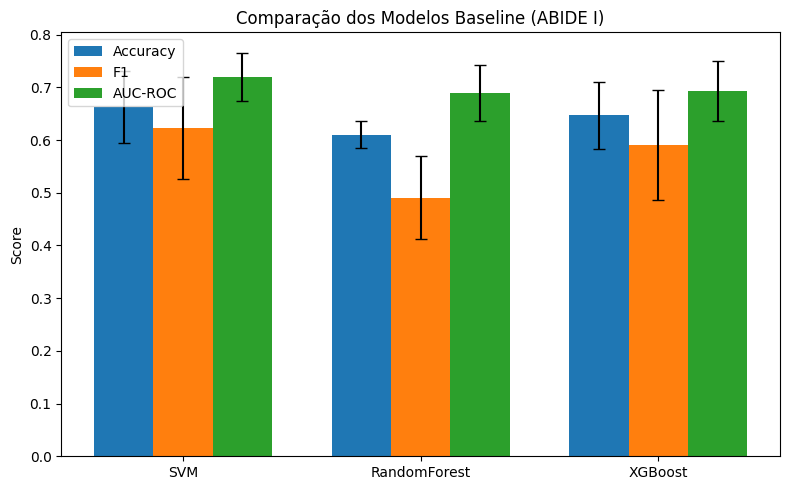

In [11]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(8, 5))
x_pos = np.arange(len(df_resultados))
largura = 0.25

ax.bar(x_pos - largura, df_resultados['accuracy_media'], largura,
       yerr=df_resultados['accuracy_std'], label='Accuracy', capsize=4)
ax.bar(x_pos, df_resultados['f1_media'], largura,
       yerr=df_resultados['f1_std'], label='F1', capsize=4)
ax.bar(x_pos + largura, df_resultados['auc_roc_media'], largura,
       yerr=df_resultados['auc_roc_std'], label='AUC-ROC', capsize=4)

ax.set_xticks(x_pos)
ax.set_xticklabels(df_resultados['modelo'])
ax.set_ylabel('Score')
ax.set_title('Comparação dos Modelos Baseline (ABIDE I)')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(PATHS['figures'], '08_comparacao_baselines.png'), dpi=300, bbox_inches='tight')
plt.show()

### Acurácia por fold

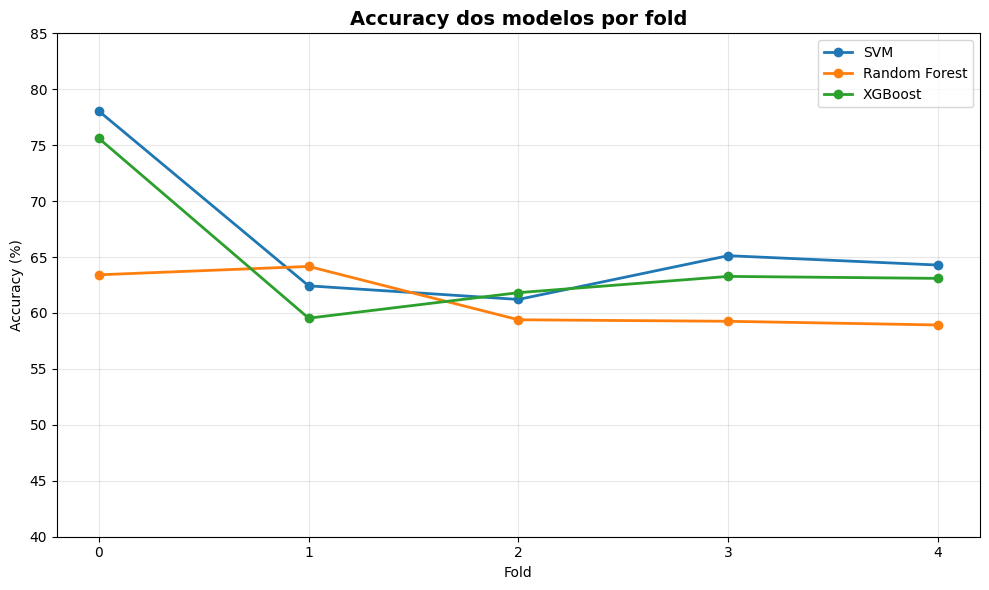

In [12]:
# ATENÇÃO: valores previamente registrados (resultados da execução original,
# copiados manualmente) — NÃO são recalculados nesta célula.

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Resultados dos 5 folds
# ------------------------------------------------------------

folds = [0, 1, 2, 3, 4]

accuracy_svm = [
    0.780488,
    0.624277,
    0.612121,
    0.651235,
    0.642857
]

accuracy_rf = [
    0.634146,
    0.641618,
    0.593939,
    0.592593,
    0.589286
]

accuracy_xgb = [
    0.756098,
    0.595376,
    0.618182,
    0.632716,
    0.630952
]


# ------------------------------------------------------------
# Criar gráfico
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    folds,
    [x * 100 for x in accuracy_svm],
    marker='o',
    linewidth=2,
    label='SVM'
)

plt.plot(
    folds,
    [x * 100 for x in accuracy_rf],
    marker='o',
    linewidth=2,
    label='Random Forest'
)

plt.plot(
    folds,
    [x * 100 for x in accuracy_xgb],
    marker='o',
    linewidth=2,
    label='XGBoost'
)


# ------------------------------------------------------------
# Configuração
# ------------------------------------------------------------

plt.title(
    'Accuracy dos modelos por fold',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel(
    'Fold'
)

plt.ylabel(
    'Accuracy (%)'
)

plt.xticks(
    folds
)

plt.ylim(
    40,
    85
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.savefig(os.path.join(PATHS['figures'], '08_accuracy_por_fold.png'), dpi=300, bbox_inches='tight')

plt.show()

### Matrizes de confusão

Matriz agregada — SVM
[[328 140]
 [171 232]]

Matriz agregada — Random Forest
[[366 102]
 [243 160]]

Matriz agregada — XGBoost
[[339 129]
 [195 208]]


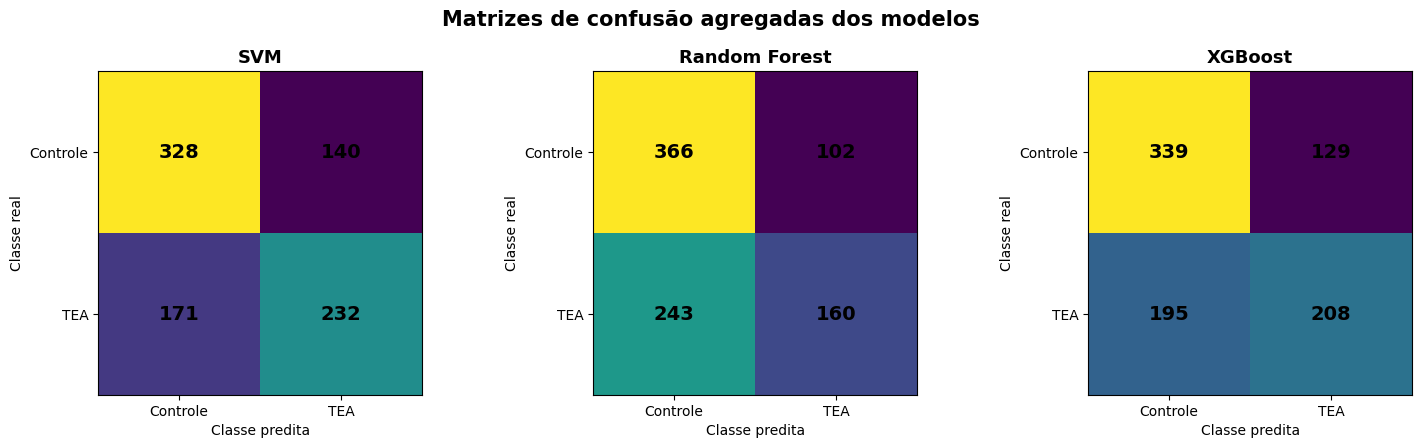

In [14]:
# ATENÇÃO: matrizes de confusão previamente registradas (resultados da execução
# original, copiados manualmente) — NÃO são recalculadas nesta célula.
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# MATRIZES DE CONFUSÃO — SVM
# ============================================================

cm_svm = np.array([

    [16, 3],
    [6, 16]

]) + np.array([

    [62, 39],
    [26, 46]

]) + np.array([

    [66, 25],
    [39, 35]

]) + np.array([

    [126, 49],
    [64, 85]

]) + np.array([

    [58, 24],
    [36, 50]

])


# ============================================================
# MATRIZES DE CONFUSÃO — RANDOM FOREST
# ============================================================

cm_rf = np.array([

    [17, 2],
    [13, 9]

]) + np.array([

    [64, 37],
    [25, 47]

]) + np.array([

    [74, 17],
    [50, 24]

]) + np.array([

    [140, 35],
    [97, 52]

]) + np.array([

    [71, 11],
    [58, 28]

])


# ============================================================
# MATRIZES DE CONFUSÃO — XGBOOST
# ============================================================

cm_xgb = np.array([

    [15, 4],
    [6, 16]

]) + np.array([

    [58, 43],
    [27, 45]

]) + np.array([

    [72, 19],
    [44, 30]

]) + np.array([

    [134, 41],
    [78, 71]

]) + np.array([

    [60, 22],
    [40, 46]

])


# ============================================================
# MOSTRAR MATRIZES
# ============================================================

print('Matriz agregada — SVM')
print(cm_svm)

print()

print('Matriz agregada — Random Forest')
print(cm_rf)

print()

print('Matriz agregada — XGBoost')
print(cm_xgb)


# ============================================================
# PLOT
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.5)
)


matrizes = [
    cm_svm,
    cm_rf,
    cm_xgb
]

nomes = [
    'SVM',
    'Random Forest',
    'XGBoost'
]


# ============================================================
# DESENHAR CADA MATRIZ
# ============================================================

for ax, cm, nome in zip(
    axes,
    matrizes,
    nomes
):

    im = ax.imshow(cm)

    ax.set_title(
        nome,
        fontsize=13,
        fontweight='bold'
    )

    ax.set_xlabel(
        'Classe predita'
    )

    ax.set_ylabel(
        'Classe real'
    )

    ax.set_xticks(
        [0, 1]
    )

    ax.set_yticks(
        [0, 1]
    )

    ax.set_xticklabels(
        ['Controle', 'TEA']
    )

    ax.set_yticklabels(
        ['Controle', 'TEA']
    )


    # --------------------------------------------------------
    # Valores dentro das células
    # --------------------------------------------------------

    for i in range(2):

        for j in range(2):

            ax.text(
                j,
                i,
                cm[i, j],
                ha='center',
                va='center',
                fontsize=14,
                fontweight='bold'
            )


plt.suptitle(
    'Matrizes de confusão agregadas dos modelos',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()

plt.savefig(os.path.join(PATHS['figures'], '08_matrizes_confusao_agregadas.png'), dpi=300, bbox_inches='tight')

plt.show()